# 섹션 분석

> 전체 보고서 중 ESG 등급과 관련성이 높을 가능성이 있는 섹션 식별하고자 한다. ESG seed 단어가 단순히 많이 나온 섹션과 실제 등급 관련성이 있는 섹션 구분하여 섹션별 E/S/G 표현량과 ESG 등급 간 관계 비교한다.

- 전체 대목차 I~XIII를 먼저 모두 추출
- 섹션별 E/S/G seed count와 정규화 count 계산
- 섹션별 seed score와 ESG 등급 간 Spearman 상관분석 수행
- 단순 출현량이 아니라 등급과의 관련성까지 고려해 주요 섹션 선정
- 최종적으로 전체 보고서 기반 분석과 섹션 기반 분석 결과를 비교

# 0. 라이브러리 및 경로 설정

In [1]:
# ============================================================
# 0. 라이브러리 및 경로 설정
# ============================================================

import json
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr

warnings.filterwarnings("ignore")

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


def find_project_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "data").exists():
            return candidate
    return Path.cwd()


PROJECT_ROOT = find_project_root()

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ANALYSIS_DIR = PROCESSED_DIR / "analysis"

REPORT_JSON_DIR = PROCESSED_DIR / "dart_full_reports"
SEED_DICT_PATH = RAW_DIR / "seed_dictionary.csv"
COMPANY_MASTER_PATH = RAW_DIR / "company_master.csv"

SECTION_ANALYSIS_DIR = ANALYSIS_DIR / "section_analysis"
SECTION_ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("REPORT_JSON_DIR:", REPORT_JSON_DIR)
print("SEED_DICT_PATH:", SEED_DICT_PATH)
print("COMPANY_MASTER_PATH:", COMPANY_MASTER_PATH)
print("SECTION_ANALYSIS_DIR:", SECTION_ANALYSIS_DIR)

PROJECT_ROOT: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final
REPORT_JSON_DIR: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\dart_full_reports
SEED_DICT_PATH: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\raw\seed_dictionary.csv
COMPANY_MASTER_PATH: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\raw\company_master.csv
SECTION_ANALYSIS_DIR: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\section_analysis


# 1. JSON 보고서 파일 불러오기

- 기업-연도별 사업보고서 JSON 파일 확인
- 섹션 기반 분석에 사용할 원천 보고서 데이터 확보

In [2]:
# ============================================================
# 1. dart_full_reports JSON 파일 확인
# ============================================================

json_files = sorted(REPORT_JSON_DIR.glob("*.json"))

print("JSON 파일 수:", len(json_files))
print(json_files[:5])

if len(json_files) == 0:
    raise FileNotFoundError("dart_full_reports 폴더에 json 파일이 없습니다.")

JSON 파일 수: 381
[WindowsPath('c:/Users/duswl/OneDrive/바탕 화면/duswls3247/비정형 데이터 처리/Final/data/processed/dart_full_reports/000020_2022.json'), WindowsPath('c:/Users/duswl/OneDrive/바탕 화면/duswls3247/비정형 데이터 처리/Final/data/processed/dart_full_reports/000020_2023.json'), WindowsPath('c:/Users/duswl/OneDrive/바탕 화면/duswls3247/비정형 데이터 처리/Final/data/processed/dart_full_reports/000020_2024.json'), WindowsPath('c:/Users/duswl/OneDrive/바탕 화면/duswls3247/비정형 데이터 처리/Final/data/processed/dart_full_reports/000040_2022.json'), WindowsPath('c:/Users/duswl/OneDrive/바탕 화면/duswls3247/비정형 데이터 처리/Final/data/processed/dart_full_reports/000040_2023.json')]


# 2. JSON에서 텍스트와 목차 정보 추출

- JSON 내부에서 본문 텍스트와 목차 후보 정보 추출
- 기업-연도별 텍스트 단위 데이터 생성

In [3]:
# ============================================================
# 2. JSON에서 text / lineage 후보 추출
# ============================================================

def flatten_records(obj):
    """
    JSON 내부를 재귀적으로 탐색하여 text와 lineage 후보를 추출
    """
    records = []

    text_keys = [
        "text",
        "full_text",
        "unit_text",
        "section_text",
        "content",
        "paragraph",
        "passage"
    ]

    lineage_keys = [
        "lineage",
        "section",
        "section_title",
        "title",
        "heading",
        "chapter",
        "toc"
    ]

    if isinstance(obj, dict):
        keys = set(obj.keys())

        has_text = any(k in keys for k in text_keys)

        if has_text:
            rec = {}

            for k in text_keys:
                if k in obj:
                    rec["text"] = obj.get(k)
                    rec["text_source_key"] = k
                    break

            for k in lineage_keys:
                if k in obj:
                    rec["lineage"] = obj.get(k)
                    rec["lineage_source_key"] = k
                    break

            if "lineage" not in rec:
                rec["lineage"] = ""
                rec["lineage_source_key"] = ""

            records.append(rec)

        for v in obj.values():
            records.extend(flatten_records(v))

    elif isinstance(obj, list):
        for item in obj:
            records.extend(flatten_records(item))

    return records


rows = []

for path in json_files:
    file_name = path.name

    # 파일명 예: 005930_2024.json
    m = re.match(r"(\d{6})_(\d{4})\.json", file_name)

    if m:
        stock_code = m.group(1)
        fiscal_year = int(m.group(2))
    else:
        stock_code = ""
        fiscal_year = np.nan

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    records = flatten_records(data)

    for i, rec in enumerate(records):
        lineage = rec.get("lineage", "")

        if isinstance(lineage, list):
            lineage = " > ".join([str(x) for x in lineage])
        else:
            lineage = str(lineage)

        text = str(rec.get("text", ""))

        rows.append({
            "source_file": file_name,
            "stock_code": stock_code,
            "fiscal_year": fiscal_year,
            "row_order": i + 1,
            "lineage": lineage,
            "text": text,
            "text_source_key": rec.get("text_source_key", ""),
            "lineage_source_key": rec.get("lineage_source_key", "")
        })

json_text_df = pd.DataFrame(rows)

json_text_df["stock_code"] = json_text_df["stock_code"].astype(str).str.zfill(6)
json_text_df["fiscal_year"] = json_text_df["fiscal_year"].astype(int)
json_text_df["analysis_unit"] = (
    json_text_df["stock_code"] + "x" + json_text_df["fiscal_year"].astype(str)
)

json_text_df["text_chars"] = json_text_df["text"].fillna("").astype(str).str.len()

print("추출된 텍스트 행 수:", len(json_text_df))
print("분석 단위 수:", json_text_df["analysis_unit"].nunique())
print(json_text_df.head())

print("\n[lineage source key 분포]")
print(json_text_df["lineage_source_key"].value_counts(dropna=False))

추출된 텍스트 행 수: 381
분석 단위 수: 381
        source_file stock_code  fiscal_year  row_order lineage  \
0  000020_2022.json     000020         2022          1           
1  000020_2023.json     000020         2023          1           
2  000020_2024.json     000020         2024          1           
3  000040_2022.json     000040         2022          1           
4  000040_2023.json     000040         2023          1           

                                                text text_source_key  \
0  사업보고서 \n5.0 \n동화약품주식회사 \n\nC \nA \n110111-0043...       full_text   
1  감사보고서 \n4.1 \n동화약품 주식회사 \n\n00469373 \n1000000...       full_text   
2  연결감사보고서 \n6.0 \n동화약품 주식회사 \n\n00469373 \n10000...       full_text   
3  사업보고서 \n5.0 \nKR모터스 \n\nC \nA \n160111-0007032...       full_text   
4  연결감사보고서 \n3.5 \n케이알모터스(주) \n\n00260295 \n10000...       full_text   

  lineage_source_key analysis_unit  text_chars  
0                      000020x2022      432677  
1                      000020x2023      44

# 3. 대목차 I~XIII 섹션 표준화

- 보고서 목차를 `I, II, III … XIII` 기준으로 정리
- 같은 섹션이 중복 집계되지 않도록 표준 섹션명 생성

In [4]:
# ============================================================
# 3. 대목차 I~XIII 기준 섹션 표준화
# ============================================================

roman_to_title = {
    "I": "I. 회사의 개요",
    "II": "II. 사업의 내용",
    "III": "III. 재무에 관한 사항",
    "IV": "IV. 이사의 경영진단 및 분석의견",
    "V": "V. 회계감사인의 감사의견 등",
    "VI": "VI. 이사회 등 회사의 기관에 관한 사항",
    "VII": "VII. 주주에 관한 사항",
    "VIII": "VIII. 임원 및 직원 등에 관한 사항",
    "IX": "IX. 계열회사 등에 관한 사항",
    "X": "X. 대주주 등과의 거래내용",
    "XI": "XI. 그 밖에 투자자 보호를 위하여 필요한 사항",
    "XII": "XII. 상세표",
    "XIII": "XIII. 부속명세서",
}

roman_order = list(roman_to_title.keys())

roman_replace_map = {
    "Ⅰ": "I",
    "Ⅱ": "II",
    "Ⅲ": "III",
    "Ⅳ": "IV",
    "Ⅴ": "V",
    "Ⅵ": "VI",
    "Ⅶ": "VII",
    "Ⅷ": "VIII",
    "Ⅸ": "IX",
    "Ⅹ": "X",
    "Ⅺ": "XI",
    "Ⅻ": "XII",
}


def normalize_roman_text(text):
    text = str(text)

    for k, v in roman_replace_map.items():
        text = text.replace(k, v)

    return text


def extract_section_roman(lineage="", text=""):
    """
    lineage 또는 text 앞부분에서 대목차 로마숫자 I~XIII 추출
    """
    raw = normalize_roman_text(str(lineage))

    if raw.strip() == "" or raw.lower() == "nan":
        raw = normalize_roman_text(str(text)[:1000])

    # 긴 로마숫자부터 먼저 매칭
    pattern = r"\b(XIII|XII|XI|X|IX|VIII|VII|VI|V|IV|III|II|I)\b\.?"

    match = re.search(pattern, raw)

    if match:
        return match.group(1)

    return "미분류"


json_text_df["section_roman"] = json_text_df.apply(
    lambda row: extract_section_roman(
        lineage=row.get("lineage", ""),
        text=row.get("text", "")
    ),
    axis=1
)

json_text_df["section_clean"] = json_text_df["section_roman"].map(roman_to_title)
json_text_df["section_clean"] = json_text_df["section_clean"].fillna("미분류")

print("섹션 분포")
print(json_text_df["section_clean"].value_counts().head(20))

print("\n표준화된 섹션 수:", json_text_df["section_clean"].nunique())

섹션 분포
section_clean
I. 회사의 개요                      221
미분류                             79
III. 재무에 관한 사항                  38
II. 사업의 내용                      17
VIII. 임원 및 직원 등에 관한 사항          11
V. 회계감사인의 감사의견 등                 5
XI. 그 밖에 투자자 보호를 위하여 필요한 사항      4
IV. 이사의 경영진단 및 분석의견              4
VI. 이사회 등 회사의 기관에 관한 사항          2
Name: count, dtype: int64

표준화된 섹션 수: 9


# 4. seed dictionary 불러오기

- E/S/G별 seed term과 정규표현식 불러오기
- 섹션별 ESG 단어 매칭 기준 준비

In [5]:
# ============================================================
# 4. seed dictionary 불러오기
# ============================================================

seed_df = pd.read_csv(SEED_DICT_PATH)
seed_df.columns = [str(c).strip() for c in seed_df.columns]

required_cols = ["dimension", "seed_term", "pattern"]

for col in required_cols:
    if col not in seed_df.columns:
        raise ValueError(f"seed_dictionary.csv에 {col} 컬럼이 없습니다.")

seed_df["dimension"] = seed_df["dimension"].astype(str).str.strip()
seed_df["seed_term"] = seed_df["seed_term"].astype(str).str.strip()
seed_df["pattern"] = seed_df["pattern"].astype(str).str.strip()

seed_df = seed_df[
    (seed_df["pattern"] != "") &
    (seed_df["pattern"].str.lower() != "nan")
].copy()

print("seed 개수:", len(seed_df))
print(seed_df["dimension"].value_counts())
print(seed_df.head())

seed 개수: 30
dimension
E    10
S    10
G    10
Name: count, dtype: int64
  dimension seed_term                 pattern  \
0         E        탄소                      탄소   
1         E      온실가스                온실가스|GHG   
2         E      탄소중립                    탄소중립   
3         E       넷제로   넷제로|net zero|net-zero   
4         E     재생에너지  재생에너지|renewable energy   

                                        source_basis  \
0  Bloomberg ESG climate change; Sautner-style cl...   
1  Bloomberg ESG climate change; GHG emissions li...   
2  Bloomberg ESG climate change; net-zero transit...   
3  Bloomberg ESG climate change; net-zero transit...   
4  Bloomberg ESG water/energy management; climate...   

                                       source_titles  \
0  Bloomberg ESG framework; Sautner-style climate...   
1  Bloomberg ESG framework; Sautner-style climate...   
2  Bloomberg ESG framework; Sautner-style climate...   
3  Bloomberg ESG framework; Sautner-style climate...   
4  Bloomberg ESG

# 5. 섹션별 E/S/G seed 출현 횟수 계산

- 각 섹션 텍스트에서 seed 단어가 몇 번 등장했는지 계산
- E/S/G 차원별 출현 횟수 산출

In [6]:
# ============================================================
# 5. 기업-연도-섹션별 E/S/G seed 출현 횟수 계산
# ============================================================

match_rows = []

for _, text_row in json_text_df.iterrows():
    analysis_unit = text_row["analysis_unit"]
    stock_code = text_row["stock_code"]
    fiscal_year = int(text_row["fiscal_year"])
    section_roman = text_row["section_roman"]
    section_clean = text_row["section_clean"]
    text = str(text_row["text"])

    if section_clean == "미분류":
        continue

    if not text.strip():
        continue

    for _, seed_row in seed_df.iterrows():
        dim = seed_row["dimension"]
        seed_term = seed_row["seed_term"]
        pattern = seed_row["pattern"]

        try:
            match_count = len(re.findall(pattern, text, flags=re.IGNORECASE))
        except re.error:
            match_count = 0

        if match_count > 0:
            match_rows.append({
                "analysis_unit": analysis_unit,
                "stock_code": stock_code,
                "fiscal_year": fiscal_year,
                "esg_year": fiscal_year + 1,
                "section_roman": section_roman,
                "section_clean": section_clean,
                "dimension": dim,
                "seed_term": seed_term,
                "match_count": match_count,
                "text_chars": len(text)
            })

section_seed_raw_df = pd.DataFrame(match_rows)

print("seed 매칭 결과 행 수:", len(section_seed_raw_df))
print(section_seed_raw_df.head())

seed 매칭 결과 행 수: 5811
  analysis_unit stock_code  fiscal_year  esg_year section_roman section_clean  \
0   000020x2022     000020         2022      2023             I     I. 회사의 개요   
1   000020x2022     000020         2022      2023             I     I. 회사의 개요   
2   000020x2022     000020         2022      2023             I     I. 회사의 개요   
3   000020x2022     000020         2022      2023             I     I. 회사의 개요   
4   000020x2022     000020         2022      2023             I     I. 회사의 개요   

  dimension seed_term  match_count  text_chars  
0         S        안전            6      432677  
1         S       임직원           26      432677  
2         S        인권           20      432677  
3         S      교육훈련           11      432677  
4         S       공급망            1      432677  


# 6. 기업-연도-섹션 단위 점수 만들기

- 기업·연도별로 섹션별 seed score 생성
- `section_seed_count_E/S/G/total` 계산
- 섹션 길이를 고려한 1,000자당 seed count 계산

In [7]:
# ============================================================
# 6. 기업-연도-섹션 단위 seed score 생성
# ============================================================

# 섹션별 텍스트 길이
section_text_len_df = (
    json_text_df[json_text_df["section_clean"] != "미분류"]
    .groupby(
        ["analysis_unit", "stock_code", "fiscal_year", "section_roman", "section_clean"],
        as_index=False
    )
    .agg(
        section_text_chars=("text_chars", "sum"),
        section_text_rows=("text", "count")
    )
)

# 섹션별 E/S/G seed count
section_score_long = (
    section_seed_raw_df
    .groupby(
        ["analysis_unit", "stock_code", "fiscal_year", "esg_year", "section_roman", "section_clean", "dimension"],
        as_index=False
    )
    .agg(seed_count=("match_count", "sum"))
)

section_score_wide = section_score_long.pivot_table(
    index=["analysis_unit", "stock_code", "fiscal_year", "esg_year", "section_roman", "section_clean"],
    columns="dimension",
    values="seed_count",
    aggfunc="sum",
    fill_value=0
).reset_index()

for dim in ["E", "S", "G"]:
    if dim not in section_score_wide.columns:
        section_score_wide[dim] = 0

section_score_wide = section_score_wide.rename(
    columns={
        "E": "section_seed_count_E",
        "S": "section_seed_count_S",
        "G": "section_seed_count_G"
    }
)

section_score_wide["section_seed_count_total"] = (
    section_score_wide["section_seed_count_E"] +
    section_score_wide["section_seed_count_S"] +
    section_score_wide["section_seed_count_G"]
)

# 텍스트 길이 붙이기
section_score_df = pd.merge(
    section_score_wide,
    section_text_len_df,
    on=["analysis_unit", "stock_code", "fiscal_year", "section_roman", "section_clean"],
    how="left"
)

# 1,000자당 seed count 정규화
section_score_df["section_seed_per_1000_chars_total"] = (
    section_score_df["section_seed_count_total"] /
    section_score_df["section_text_chars"].replace(0, np.nan) * 1000
)

for dim in ["E", "S", "G"]:
    section_score_df[f"section_seed_per_1000_chars_{dim}"] = (
        section_score_df[f"section_seed_count_{dim}"] /
        section_score_df["section_text_chars"].replace(0, np.nan) * 1000
    )

section_score_df = section_score_df.fillna(0)

print("기업-연도-섹션 점수 데이터 수:", len(section_score_df))
print(section_score_df.head())

기업-연도-섹션 점수 데이터 수: 302
  analysis_unit stock_code  fiscal_year  esg_year section_roman section_clean  \
0   000020x2022     000020         2022      2023             I     I. 회사의 개요   
1   000020x2023     000020         2023      2024             I     I. 회사의 개요   
2   000020x2024     000020         2024      2025             I     I. 회사의 개요   
3   000040x2022     000040         2022      2023             I     I. 회사의 개요   
4   000040x2024     000040         2024      2025             I     I. 회사의 개요   

   section_seed_count_E  section_seed_count_G  section_seed_count_S  \
0                     0                   261                    64   
1                     0                   260                    63   
2                     0                   259                    65   
3                    28                   223                    26   
4                     5                   229                    30   

   section_seed_count_total  section_text_chars  section_text_r

# 7. ESG 등급 데이터 병합

- 섹션별 seed score와 실제 ESG 등급 연결
- 병합 기준: `stock_code`, `fiscal_year`, `esg_year`

In [8]:
# ============================================================
# 7. ESG 등급 데이터 병합
# ============================================================

grade_df = pd.read_csv(COMPANY_MASTER_PATH, dtype={"stock_code": str})
grade_df.columns = [str(c).strip() for c in grade_df.columns]

grade_df["stock_code"] = (
    grade_df["stock_code"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(6)
)

grade_df["fiscal_year"] = grade_df["fiscal_year"].astype(int)

if "esg_year" in grade_df.columns:
    grade_df["esg_year"] = grade_df["esg_year"].astype(int)
else:
    grade_df["esg_year"] = grade_df["fiscal_year"] + 1

grade_map = {
    "D": 0,
    "C": 1,
    "B": 2,
    "B+": 3,
    "A": 4,
    "A+": 5,
    "S": 6
}

if "esg_grade_num" not in grade_df.columns:
    grade_df["esg_grade"] = grade_df["esg_grade"].astype(str).str.strip()
    grade_df["esg_grade_num"] = grade_df["esg_grade"].map(grade_map)

grade_cols = [
    "stock_code",
    "fiscal_year",
    "esg_year",
    "esg_grade",
    "esg_grade_num"
]

for c in ["company_name", "e_grade", "s_grade", "g_grade"]:
    if c in grade_df.columns:
        grade_cols.append(c)

section_analysis_df = pd.merge(
    section_score_df,
    grade_df[grade_cols],
    on=["stock_code", "fiscal_year", "esg_year"],
    how="inner"
)

print("섹션 분석 데이터 수:", len(section_analysis_df))
print("분석 단위 수:", section_analysis_df["analysis_unit"].nunique())
print(section_analysis_df.head())

섹션 분석 데이터 수: 302
분석 단위 수: 302
  analysis_unit stock_code  fiscal_year  esg_year section_roman section_clean  \
0   000020x2022     000020         2022      2023             I     I. 회사의 개요   
1   000020x2023     000020         2023      2024             I     I. 회사의 개요   
2   000020x2024     000020         2024      2025             I     I. 회사의 개요   
3   000040x2022     000040         2022      2023             I     I. 회사의 개요   
4   000040x2024     000040         2024      2025             I     I. 회사의 개요   

   section_seed_count_E  section_seed_count_G  section_seed_count_S  \
0                     0                   261                    64   
1                     0                   260                    63   
2                     0                   259                    65   
3                    28                   223                    26   
4                     5                   229                    30   

   section_seed_count_total  ...  section_seed_per_1000_

# 8. 섹션별 ESG 등급 관련성 분석

- 섹션별 seed score와 ESG 등급 간 Spearman 상관분석
- 어떤 섹션이 ESG 등급과 관련성이 높은지 확인

In [9]:
# ============================================================
# 8. 섹션별 ESG 등급 관련성 Spearman 분석
# ============================================================

section_corr_rows = []

score_cols = [
    "section_seed_count_E",
    "section_seed_count_S",
    "section_seed_count_G",
    "section_seed_count_total",
    "section_seed_per_1000_chars_E",
    "section_seed_per_1000_chars_S",
    "section_seed_per_1000_chars_G",
    "section_seed_per_1000_chars_total",
]

for section_name, temp in section_analysis_df.groupby("section_clean"):
    n_units = temp["analysis_unit"].nunique()

    for score_col in score_cols:
        if temp[score_col].nunique() <= 1:
            corr, pval = np.nan, np.nan
        else:
            corr, pval = spearmanr(temp[score_col], temp["esg_grade_num"])

        section_corr_rows.append({
            "section_clean": section_name,
            "score_col": score_col,
            "n_units": n_units,
            "spearman_corr": corr,
            "p_value": pval,
            "mean_score": temp[score_col].mean(),
            "sum_score": temp[score_col].sum()
        })

section_corr_df = pd.DataFrame(section_corr_rows)

section_corr_df = section_corr_df.sort_values(
    ["spearman_corr"],
    ascending=False
).reset_index(drop=True)

print(section_corr_df.head(30))

                  section_clean                          score_col  n_units  \
0           IV. 이사의 경영진단 및 분석의견  section_seed_per_1000_chars_total        4   
1           IV. 이사의 경영진단 및 분석의견      section_seed_per_1000_chars_G        4   
2           IV. 이사의 경영진단 및 분석의견               section_seed_count_G        4   
3           IV. 이사의 경영진단 및 분석의견           section_seed_count_total        4   
4        VIII. 임원 및 직원 등에 관한 사항           section_seed_count_total       11   
5   XI. 그 밖에 투자자 보호를 위하여 필요한 사항               section_seed_count_S        4   
6   XI. 그 밖에 투자자 보호를 위하여 필요한 사항      section_seed_per_1000_chars_E        4   
7   XI. 그 밖에 투자자 보호를 위하여 필요한 사항               section_seed_count_G        4   
8   XI. 그 밖에 투자자 보호를 위하여 필요한 사항           section_seed_count_total        4   
9   XI. 그 밖에 투자자 보호를 위하여 필요한 사항               section_seed_count_E        4   
10                    I. 회사의 개요           section_seed_count_total      221   
11       VIII. 임원 및 직원 등에 관한 사항               sectio

# 9. 주요 섹션 선별

- 출현량 충분
- 상관계수 양수
- p-value 유의
- ESG 등급과 관련성이 있는 섹션 후보 도출

In [10]:
# ============================================================
# 9. 주요 섹션 선별
# ============================================================

meaningful_sections = section_corr_df[
    (section_corr_df["n_units"] >= 30) &
    (section_corr_df["spearman_corr"] > 0) &
    (section_corr_df["p_value"] < 0.05)
].copy()

meaningful_sections = meaningful_sections.sort_values(
    ["spearman_corr", "sum_score"],
    ascending=[False, False]
)

print("ESG 등급과 유의한 양의 관계를 보이는 섹션-지표")
print(meaningful_sections.head(30))

selected_section_names = meaningful_sections["section_clean"].drop_duplicates().tolist()

print("\n선별된 주요 섹션:")
for s in selected_section_names:
    print("-", s)

ESG 등급과 유의한 양의 관계를 보이는 섹션-지표
     section_clean                          score_col  n_units  spearman_corr  \
10       I. 회사의 개요           section_seed_count_total      221       0.752483   
12       I. 회사의 개요               section_seed_count_G      221       0.745754   
14  III. 재무에 관한 사항               section_seed_count_S       38       0.716070   
15       I. 회사의 개요               section_seed_count_S      221       0.713991   
17  III. 재무에 관한 사항           section_seed_count_total       38       0.638232   
18  III. 재무에 관한 사항               section_seed_count_G       38       0.637099   
21  III. 재무에 관한 사항      section_seed_per_1000_chars_S       38       0.484859   
22       I. 회사의 개요               section_seed_count_E      221       0.479700   
24  III. 재무에 관한 사항               section_seed_count_E       38       0.458991   
27       I. 회사의 개요      section_seed_per_1000_chars_S      221       0.371763   
29       I. 회사의 개요      section_seed_per_1000_chars_E      221       0.322039   

# 10. 전체 섹션별 seed count 시각화

- I~XIII 섹션별 E/S/G seed 단어 출현 횟수 비교
- ESG 표현이 많이 등장한 섹션 확인

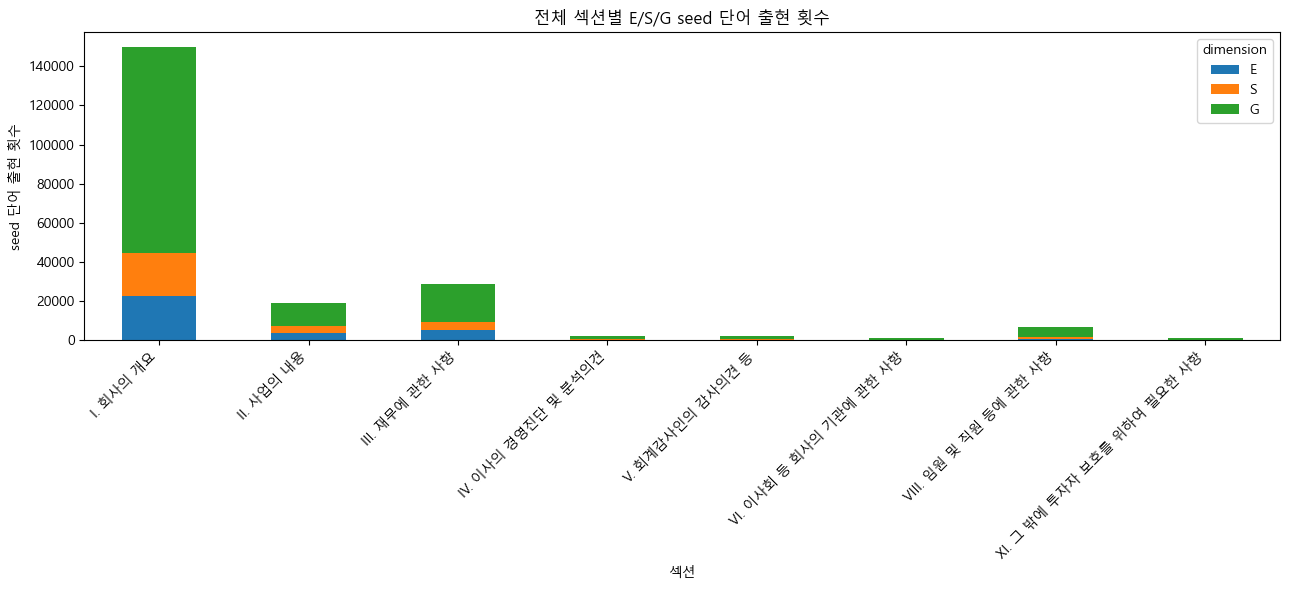

,section_roman,section_clean,section_seed_count_E,section_seed_count_S,section_seed_count_G,section_order
0,I,I. 회사의 개요,22522,22097,105419,0
1,II,II. 사업의 내용,3616,3709,11610,1
2,III,III. 재무에 관한 사항,5159,4376,19349,2
3,IV,IV. 이사의 경영진단 및 분석의견,258,267,1887,3
4,V,V. 회계감사인의 감사의견 등,246,278,1728,4
5,VI,VI. 이사회 등 회사의 기관에 관한 사항,111,117,1143,5
6,VIII,VIII. 임원 및 직원 등에 관한 사항,507,1187,5013,7
7,XI,XI. 그 밖에 투자자 보호를 위하여 필요한 사항,128,251,1028,10


In [11]:
# ============================================================
# 10. 전체 섹션별 E/S/G seed count 시각화
# ============================================================

section_total_pivot = (
    section_analysis_df
    .groupby(["section_roman", "section_clean"], as_index=False)[
        ["section_seed_count_E", "section_seed_count_S", "section_seed_count_G"]
    ]
    .sum()
)

section_total_pivot["section_order"] = section_total_pivot["section_roman"].apply(
    lambda x: roman_order.index(x) if x in roman_order else 999
)

section_total_pivot = section_total_pivot.sort_values("section_order")

plot_df = section_total_pivot.set_index("section_clean")[
    ["section_seed_count_E", "section_seed_count_S", "section_seed_count_G"]
]

plot_df.columns = ["E", "S", "G"]

plot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6)
)

plt.xlabel("섹션")
plt.ylabel("seed 단어 출현 횟수")
plt.title("전체 섹션별 E/S/G seed 단어 출현 횟수")
plt.xticks(rotation=45, ha="right")
plt.legend(title="dimension")
plt.tight_layout()
plt.show()

section_total_pivot

# 11. 섹션별 정규화 점수 시각화

- 섹션 길이 차이를 보정한 ESG seed 밀도 비교
- 긴 섹션이 유리한 문제 완화

                 section_clean  total_seed_count  total_text_chars  \
5      VI. 이사회 등 회사의 기관에 관한 사항              1371            774452   
2               III. 재무에 관한 사항             28884          19460360   
4             V. 회계감사인의 감사의견 등              2252           1616473   
7  XI. 그 밖에 투자자 보호를 위하여 필요한 사항              1407           1120599   
3          IV. 이사의 경영진단 및 분석의견              2412           1935268   
1                   II. 사업의 내용             18935          15605827   
6       VIII. 임원 및 직원 등에 관한 사항              6707           5609441   
0                    I. 회사의 개요            150038         126589006   

   seed_per_1000_chars  
5             1.770284  
2             1.484248  
4             1.393157  
7             1.255578  
3             1.246339  
1             1.213329  
6             1.195663  
0             1.185237  


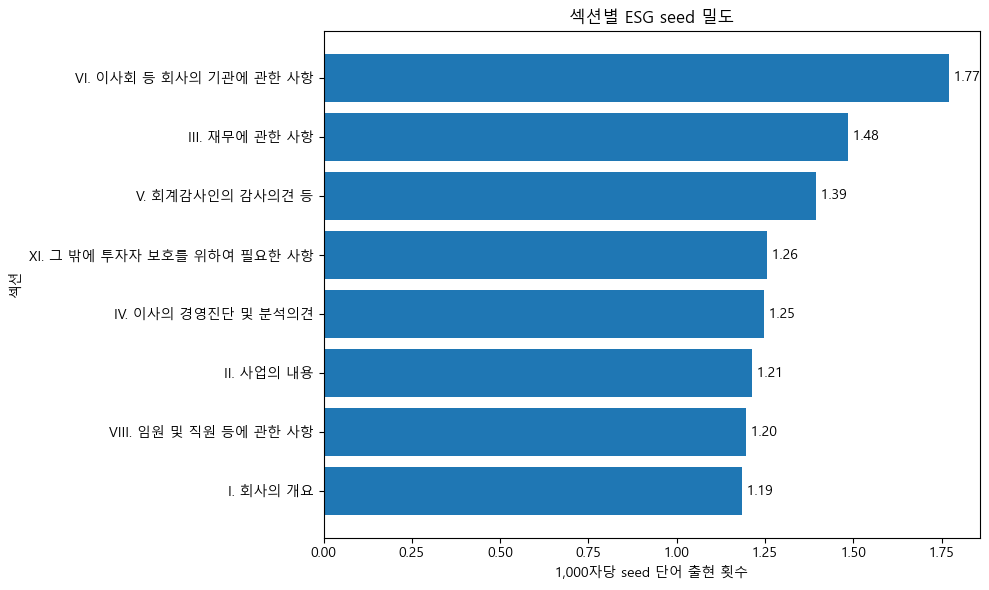

In [12]:
# ============================================================
# 11. 전체 섹션별 1,000자당 seed count 시각화
# ============================================================

section_norm_df = (
    section_analysis_df
    .groupby(["section_roman", "section_clean"], as_index=False)
    .agg(
        total_seed_count=("section_seed_count_total", "sum"),
        total_text_chars=("section_text_chars", "sum")
    )
)

section_norm_df["seed_per_1000_chars"] = (
    section_norm_df["total_seed_count"] /
    section_norm_df["total_text_chars"].replace(0, np.nan) * 1000
)

section_norm_df = section_norm_df.fillna(0)

section_norm_df["section_order"] = section_norm_df["section_roman"].apply(
    lambda x: roman_order.index(x) if x in roman_order else 999
)

section_norm_df = section_norm_df.sort_values("seed_per_1000_chars", ascending=False)

print(section_norm_df[["section_clean", "total_seed_count", "total_text_chars", "seed_per_1000_chars"]])

plt.figure(figsize=(10, 6))

plt.barh(
    section_norm_df["section_clean"][::-1],
    section_norm_df["seed_per_1000_chars"][::-1]
)

plt.xlabel("1,000자당 seed 단어 출현 횟수")
plt.ylabel("섹션")
plt.title("섹션별 ESG seed 밀도")

for i, v in enumerate(section_norm_df["seed_per_1000_chars"][::-1]):
    plt.text(v, i, f" {v:.2f}", va="center")

plt.tight_layout()
plt.show()

# 12. 섹션별 상관계수 시각화

- 각 섹션의 seed score와 ESG 등급 간 상관계수 시각화
- 단순히 많이 나온 섹션이 아니라 등급과 관련 있는 섹션 확인

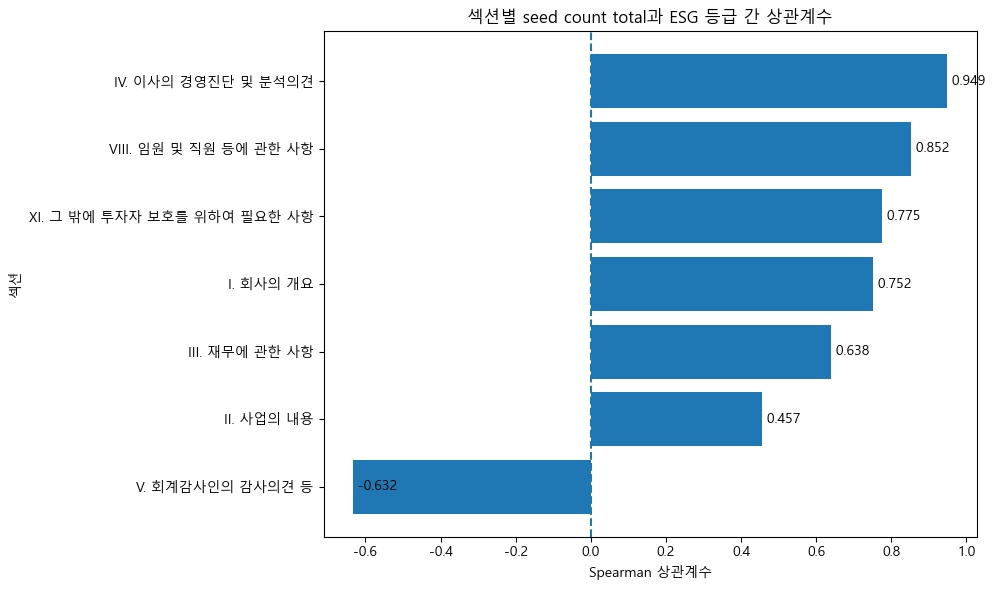

,section_clean,n_units,spearman_corr,p_value,sum_score
3,IV. 이사의 경영진단 및 분석의견,4,0.948683,5.131670e-02,2412.0
4,VIII. 임원 및 직원 등에 관한 사항,11,0.852296,8.614196e-04,6707.0
8,XI. 그 밖에 투자자 보호를 위하여 필요한 사항,4,0.774597,2.254033e-01,1407.0
10,I. 회사의 개요,221,0.752483,1.358634e-41,150038.0
17,III. 재무에 관한 사항,38,0.638232,1.625368e-05,28884.0
25,II. 사업의 내용,17,0.456775,6.529973e-02,18935.0
51,V. 회계감사인의 감사의견 등,5,-0.632456,2.522155e-01,2252.0


In [13]:
# ============================================================
# 12. 섹션별 total seed count와 ESG 등급 간 상관계수 시각화
# ============================================================

corr_plot_df = section_corr_df[
    section_corr_df["score_col"] == "section_seed_count_total"
].copy()

corr_plot_df = corr_plot_df.dropna(subset=["spearman_corr"])
corr_plot_df = corr_plot_df.sort_values("spearman_corr", ascending=False)

plt.figure(figsize=(10, 6))

plt.barh(
    corr_plot_df["section_clean"][::-1],
    corr_plot_df["spearman_corr"][::-1]
)

plt.axvline(0, linestyle="--")

plt.xlabel("Spearman 상관계수")
plt.ylabel("섹션")
plt.title("섹션별 seed count total과 ESG 등급 간 상관계수")

for i, v in enumerate(corr_plot_df["spearman_corr"][::-1]):
    plt.text(v, i, f" {v:.3f}", va="center")

plt.tight_layout()
plt.show()

corr_plot_df[["section_clean", "n_units", "spearman_corr", "p_value", "sum_score"]]

# 13. 결과 저장

In [14]:
# ============================================================
# 13. 섹션 기반 분석 결과 저장
# ============================================================

section_score_path = SECTION_ANALYSIS_DIR / "section_score_by_firm_year.csv"
section_corr_path = SECTION_ANALYSIS_DIR / "section_spearman_result.csv"
meaningful_section_path = SECTION_ANALYSIS_DIR / "meaningful_sections.csv"

section_analysis_df.to_csv(
    section_score_path,
    index=False,
    encoding="utf-8-sig"
)

section_corr_df.to_csv(
    section_corr_path,
    index=False,
    encoding="utf-8-sig"
)

meaningful_sections.to_csv(
    meaningful_section_path,
    index=False,
    encoding="utf-8-sig"
)

print("저장 완료:", section_score_path)
print("저장 완료:", section_corr_path)
print("저장 완료:", meaningful_section_path)

저장 완료: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\section_analysis\section_score_by_firm_year.csv
저장 완료: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\section_analysis\section_spearman_result.csv
저장 완료: c:\Users\duswl\OneDrive\바탕 화면\duswls3247\비정형 데이터 처리\Final\data\processed\analysis\section_analysis\meaningful_sections.csv
